# Búsqueda Tabú

**Serie:** Metaheurísticas desde cero · **Bloque:** 2 – Métodos con memoria · **Notebook 06**

Anterior: [Recocido simulado](../01-metodos-de-trayectoria/05-aleatorizados-recocido-simulado.ipynb) ·
Siguiente: [GRASP y Path Relinking](07-grasp-path-relinking.ipynb) ·
Después: [Colonia de hormigas](08-colonia-de-hormigas.ipynb)

## Tabla de contenido
1. Qué vas a aprender y prerrequisitos
2. Intuición: por qué una búsqueda local necesita memoria
3. Formulación: vecindario, memoria de corto plazo, aspiración
4. Pseudocódigo
5. Utilidades: TSP euclídeo y movimiento 2-opt con su delta (verificado)
6. Búsqueda tabú para TSP: implementación completa
7. Experimentos de corto plazo: efecto de la tenencia, aspiración, tenencia aleatoria y reactiva
8. Tabú sobre atributos vs sobre soluciones
9. Lista de candidatos
10. Memoria de mediano y largo plazo: intensificación y diversificación
11. Trayectoria de la búsqueda
12. *Robust Tabu Search* de Taillard para QAP (matriz de deltas con actualización $O(1)$)
13. Ventajas, limitaciones, resumen, ejercicios y referencias

## 1. Qué vas a aprender y prerrequisitos

**Objetivo.** Entender la búsqueda tabú (TS, *Tabu Search*) como una búsqueda local con **memoria adaptativa** que le permite
atravesar óptimos locales sin ciclar, e implementarla desde cero para dos problemas permutacionales: el **TSP** (vecindario 2-opt)
y el **QAP** (vecindario de intercambio de pares, con el esquema *Robust Tabu Search* de Taillard).

**Al terminar sabrás:**
- distinguir memoria de corto, mediano y largo plazo y qué decisión controla cada una;
- elegir *atributos* tabú, tenencia (fija, aleatoria, reactiva) y criterios de aspiración;
- usar listas de candidatos para abaratar la evaluación del vecindario;
- implementar el cálculo incremental de deltas del QAP y actualizar la matriz de deltas en $O(1)$ por par;
- medir el efecto de cada parámetro con varias semillas y reportar media $\pm$ desviación estándar.

**Prerrequisitos.** Búsqueda local y vecindarios ([notebook 03](../01-metodos-de-trayectoria/03-busqueda-local-ils.ipynb)),
nociones de TSP y QAP ([notebook 01](../00-fundamentos/01-introduccion-optimizacion-combinatoria.ipynb)), NumPy básico.

In [1]:
import time, warnings
import numpy as np
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
rng_global = np.random.default_rng(2024)   # semilla fija del notebook
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
print("NumPy", np.__version__)

NumPy 2.5.4


## 2. Intuición

Una búsqueda local de *mejor mejora* se detiene en el primer óptimo local: ningún vecino mejora la solución actual.
El recocido simulado escapa **aleatoriamente** (acepta empeoramientos con cierta probabilidad). La búsqueda tabú escapa de forma
**determinista y dirigida por la historia**: siempre se mueve al *mejor vecino permitido*, aunque empeore, y para no regresar
inmediatamente al óptimo del que salió, **prohíbe** (declara *tabú*) ciertos movimientos o atributos durante un tiempo.

> **Analogía.** Exploras una ciudad desconocida buscando el mejor café. Después de visitar un local anotas en una libreta
> "no volver a esta calle durante 10 paseos". La libreta es la lista tabú: te obliga a probar calles nuevas aunque la
> siguiente peor opción sea peor que el café del que vienes. Si una calle prohibida resulta tener un café mejor que cualquiera
> visto antes, rompes la regla (**aspiración**).

Tres tipos de memoria (Glover, 1986, 1989–1990):

| Memoria | Qué guarda | Qué controla | Mecanismo típico |
|---|---|---|---|
| **Corto plazo** (recencia) | atributos de movimientos recientes | evita ciclos inmediatos | lista tabú con tenencia $\tau$ |
| **Mediano plazo** | soluciones élite | **intensificación** | reinicios desde élites, fijar atributos comunes |
| **Largo plazo** (frecuencia) | cuántas veces ocurrió cada atributo | **diversificación** | penalizar atributos muy frecuentes, reinicios |

## 3. Formulación

Sea $S$ el espacio de soluciones, $f:S\to\mathbb{R}$ la función a minimizar y $N(s)$ el vecindario de $s$. En la iteración $k$:

$$
s_{k+1} = \arg\min_{s' \in N^{*}(s_k)} f(s'), \qquad
N^{*}(s_k) = \{\,s'\in N(s_k) : m(s_k\to s') \notin T_k\,\} \;\cup\; \{\,s' : f(s') < f^{\text{mejor}}\,\}
$$

donde $T_k$ es el conjunto de **movimientos (o atributos) tabú** vigentes y la segunda unión es el **criterio de aspiración por
objetivo**: un movimiento tabú se acepta si produce una solución mejor que la mejor encontrada hasta ahora.

**Atributos.** Almacenar soluciones completas es caro y deja pasar ciclos "casi iguales". Se prefiere almacenar *atributos* del
movimiento. En el TSP con 2-opt, un movimiento elimina las aristas $(a,b)$ y $(c,d)$ y agrega $(a,c)$ y $(b,d)$. Prohibimos
**volver a agregar** las aristas eliminadas durante $\tau$ iteraciones: un movimiento es tabú si alguna arista que agrega está
en la lista. En el QAP, el atributo es el par (unidad $i$, ubicación $\ell$): se prohíbe que la unidad $i$ regrese a $\ell$.

**Tenencia $\tau$ (*tabu tenure*).** Si es muy corta, aparecen ciclos; si es muy larga, el vecindario permitido se agota y la
búsqueda queda "estrangulada". Variantes: fija, aleatoria en $[\tau_{\min},\tau_{\max}]$ (rompe ciclos periódicos de longitud
fija) y **reactiva** (Battiti & Tecchiolli, 1994), que aumenta $\tau$ al detectar soluciones repetidas y lo reduce tras un periodo sin repeticiones.

**Tamaño del vecindario.** 2-opt en un tour de $n$ ciudades tiene $\binom{n}{2}-n=\tfrac{n(n-3)}{2}$ movimientos distintos
(excluyendo los que no cambian el tour). Para $n=50$ son $1175$. El intercambio de pares del QAP tiene $\binom{n}{2}$ vecinos
($190$ para $n=20$).

## 4. Pseudocódigo

```
TABU_SEARCH(s0, max_iter, τ):
    s ← s0;  mejor ← s0;  T ← ∅ (lista tabú con vencimientos)
    para k = 1 .. max_iter:
        para cada movimiento m en N(s):
            permitido(m) ← (m no es tabú) O (f(s ⊕ m) < f(mejor))      # aspiración
        m* ← argmin_{m permitido} f(s ⊕ m)  (+ penalización de frecuencia, si hay)
        si no hay permitidos: m* ← movimiento con vencimiento más próximo
        s ← s ⊕ m*
        registrar en T los atributos que m* deshizo, con vencimiento k + τ
        actualizar frecuencias, élites
        si f(s) < f(mejor): mejor ← s
        si pasaron P iteraciones sin mejorar:        # mediano plazo
            s ← elegir élite; limpiar T               # intensificación
    devolver mejor
```

## 5. Utilidades: TSP y movimiento 2-opt

Generamos una instancia euclídea aleatoria y definimos el delta de 2-opt. Como la **búsqueda tabú evalúa todo el vecindario en
cada iteración**, vectorizamos el cálculo de los deltas de los $\sim n^2/2$ movimientos con NumPy.

Para un tour $t$ y $b=\text{roll}(t,-1)$ (sucesor de cada ciudad), el movimiento $(i,j)$ con $i<j$ invierte el segmento
$t[i+1..j]$:

$$
\Delta(i,j) = d(t_i,t_j) + d(t_{i+1},t_{j+1}) - d(t_i,t_{i+1}) - d(t_j,t_{j+1}).
$$

In [2]:
def crear_tsp(n, rng):
    # Instancia euclídea: n puntos en el cuadrado unitario.
    P = rng.random((n, 2))
    D = np.sqrt(((P[:, None, :] - P[None, :, :]) ** 2).sum(-1))
    return P, D

def largo_tour(D, t):
    return D[t, np.roll(t, -1)].sum()

def es_permutacion(t, n):
    # Valida que el tour visite cada ciudad exactamente una vez.
    return len(t) == n and np.array_equal(np.sort(t), np.arange(n))

def pares_2opt(n):
    # Pares (i,j) con i<j, j>=i+2, excluyendo (0,n-1) (mismo tour, aristas adyacentes).
    I, J = np.triu_indices(n, 2)
    m = ~((I == 0) & (J == n - 1))
    return I[m], J[m]

def deltas_2opt(D, t, I, J):
    # Vector con el delta de cada movimiento 2-opt (i,j) de la lista (I,J).
    a = t; b = np.roll(t, -1)
    ai, aj, bi, bj = a[I], a[J], b[I], b[J]
    return D[ai, aj] + D[bi, bj] - D[ai, bi] - D[aj, bj]

def aplicar_2opt(t, i, j):
    # Invierte el segmento t[i+1..j] (devuelve una copia).
    u = t.copy()
    u[i + 1:j + 1] = u[i + 1:j + 1][::-1]
    return u

# Verificación: el delta incremental debe coincidir con recalcular el largo completo.
rng = np.random.default_rng(1)
n_test = 40
P_t, D_t = crear_tsp(n_test, rng)
t = rng.permutation(n_test)
I_t, J_t = pares_2opt(n_test)
dl = deltas_2opt(D_t, t, I_t, J_t)
err = 0.0
for k in range(len(I_t)):
    u = aplicar_2opt(t, I_t[k], J_t[k])
    assert es_permutacion(u, n_test)
    err = max(err, abs((largo_tour(D_t, u) - largo_tour(D_t, t)) - dl[k]))
print(f"Movimientos 2-opt: {len(I_t)} (esperado n(n-3)/2 = {n_test*(n_test-3)//2})")
print(f"Máximo error |delta incremental - recomputación completa| = {err:.2e}")

Movimientos 2-opt: 740 (esperado n(n-3)/2 = 740)
Máximo error |delta incremental - recomputación completa| = 5.27e-15


## 6. Búsqueda tabú para TSP

Implementamos un único motor con interruptores para todas las variantes que estudiaremos:

- `tenencia`: `("fija", v)`, `("aleatoria", (lo, hi))` o `("reactiva", v0)`.
- `aspiracion`: aceptar movimientos tabú que mejoran el mejor global.
- `k_cand`: lista de candidatos (solo movimientos que agregan una arista entre vecinos cercanos).
- `lam`: peso de la **penalización por frecuencia** (memoria de largo plazo).
- `paciencia`: tras ese número de iteraciones sin mejorar el mejor, **reiniciar desde una solución élite** (mediano plazo).
- `tipo`: `"atributos"` (aristas) o `"soluciones"` (se prohíbe re-visitar tours completos).

La memoria de corto plazo es una matriz `E[u,v]` con la iteración hasta la cual la arista $(u,v)$ no puede volver a agregarse.
Para detectar ciclos guardamos una clave canónica de cada tour visitado (rotación y sentido normalizados).

In [3]:
def clave_tour(t):
    # Clave canónica: empieza en la ciudad 0 y recorre en el sentido con menor segundo elemento.
    p = int(np.where(t == 0)[0][0])
    r = np.roll(t, -p)
    if r[1] > r[-1]:
        r = np.concatenate(([0], r[1:][::-1]))
    return r.tobytes()

def mascara_knn(D, k):
    # Matriz booleana simétrica: True si v es uno de los k vecinos más cercanos de u (o viceversa).
    n = len(D)
    M = np.zeros((n, n), bool)
    vec = np.argsort(D, axis=1)[:, 1:k + 1]
    M[np.repeat(np.arange(n), k), vec.ravel()] = True
    return M | M.T

def tabu_tsp(D, iters, rng, tenencia=("fija", 10), aspiracion=True, k_cand=None, lam=0.0,
             paciencia=None, elite_k=5, tipo="atributos", init=None, registrar=False):
    # Búsqueda tabú con vecindario 2-opt completo (vectorizado).
    n = len(D)
    t = rng.permutation(n) if init is None else init.copy()
    L = largo_tour(D, t)
    mejor, t_mejor = L, t.copy()
    I, J = pares_2opt(n)
    E = np.zeros((n, n), dtype=np.int64)      # vencimiento tabú de cada arista
    F = np.zeros((n, n))                      # frecuencia con que se agregó cada arista
    nn = mascara_knn(D, k_cand) if k_cand else None
    escala = D.mean()
    modo, par = tenencia
    ten = par if modo in ("fija", "reactiva") else None
    visitadas = {clave_tour(t): 1}
    repeticiones = 0; reinicios = 0; ult_mej = 0; ult_cambio = 0
    elite = [(L, t.copy())]
    h_act, h_mej = [], []
    for it in range(1, iters + 1):
        a = t; b = np.roll(t, -1)
        ai, aj, bi, bj = a[I], a[J], b[I], b[J]
        delta = D[ai, aj] + D[bi, bj] - D[ai, bi] - D[aj, bj]
        puntaje = delta + lam * escala * (F[ai, aj] + F[bi, bj]) / it   # penalización de frecuencia
        if nn is not None:
            puntaje = np.where(nn[ai, aj] | nn[bi, bj], puntaje, np.inf)
        if tipo == "atributos":
            tabu = (E[ai, aj] >= it) | (E[bi, bj] >= it)
            ok = ~tabu
            if aspiracion:
                ok |= (L + delta < mejor - 1e-12)
            cand = np.where(ok, puntaje, np.inf)
            k = int(np.argmin(cand))
            if not np.isfinite(cand[k]):                 # todo tabú: se elige el de vencimiento más próximo
                k = int(np.argmin(np.where(np.isfinite(puntaje), np.maximum(E[ai, aj], E[bi, bj]), np.inf)))
        else:                                            # tabú sobre soluciones completas
            orden = np.argsort(puntaje)
            k = int(orden[0])
            for kk in orden[:60]:
                if not np.isfinite(puntaje[kk]):
                    break
                if clave_tour(aplicar_2opt(t, I[kk], J[kk])) not in visitadas:
                    k = int(kk); break
        i, j = int(I[k]), int(J[k])
        # registrar aristas eliminadas como tabú y aristas agregadas en frecuencia
        if tipo == "atributos":
            if modo == "aleatoria":
                ten = int(rng.integers(par[0], par[1] + 1))
            for (u, v) in ((a[i], b[i]), (a[j], b[j])):
                E[u, v] = E[v, u] = it + ten
        F[a[i], a[j]] += 1; F[a[j], a[i]] += 1; F[b[i], b[j]] += 1; F[b[j], b[i]] += 1
        t = aplicar_2opt(t, i, j)
        L = L + delta[k]
        cl = clave_tour(t)
        if cl in visitadas:
            repeticiones += 1
            if modo == "reactiva":
                ten = min(n, int(ten * 1.2) + 1); ult_cambio = it
        visitadas[cl] = visitadas.get(cl, 0) + 1
        if modo == "reactiva" and it - ult_cambio > 50:
            ten = max(2, int(ten * 0.9)); ult_cambio = it
        if L < mejor - 1e-12:
            mejor, t_mejor, ult_mej = L, t.copy(), it
        if len(elite) < elite_k or L < elite[-1][0] - 1e-12:
            if all(clave_tour(e[1]) != cl for e in elite):
                elite.append((L, t.copy())); elite.sort(key=lambda e: e[0]); elite = elite[:elite_k]
        if paciencia and it - ult_mej >= paciencia:      # intensificación: reinicio desde una élite
            L, t = elite[int(rng.integers(len(elite)))]; t = t.copy()
            E[:] = 0; ult_mej = it; reinicios += 1
        if registrar:
            h_act.append(L); h_mej.append(mejor)
    assert es_permutacion(t_mejor, n) and abs(largo_tour(D, t_mejor) - mejor) < 1e-8
    return dict(mejor=mejor, tour=t_mejor, rep=repeticiones / iters, reinicios=reinicios,
                act=np.array(h_act), mej=np.array(h_mej), ten_final=ten)

# Instancia principal de los experimentos TSP
N_TSP = 50
P, D = crear_tsp(N_TSP, np.random.default_rng(7))
res = tabu_tsp(D, 1500, np.random.default_rng(0), tenencia=("fija", 10), registrar=True)
print(f"TS (tenencia fija 10), 1500 iteraciones: mejor = {res['mejor']:.4f}; fracción de tours repetidos = {res['rep']:.3f}")

TS (tenencia fija 10), 1500 iteraciones: mejor = 6.1566; fracción de tours repetidos = 0.799


### Línea base honesta: búsqueda local con reinicios aleatorios

Antes de interpretar resultados, necesitamos un adversario. Usamos 2-opt de *mejor mejora* con reinicios aleatorios y el
**mismo número de iteraciones de vecindario completo** (cada iteración de TS evalúa un vecindario completo, igual que cada paso
de la búsqueda local).

In [4]:
def ls_2opt(D, t, I, J, max_pasos=100000):
    # Búsqueda local 2-opt, mejor mejora. Devuelve (tour, largo, pasos).
    t = t.copy(); L = largo_tour(D, t); pasos = 0
    while pasos < max_pasos:
        d = deltas_2opt(D, t, I, J)
        k = int(np.argmin(d))
        if d[k] >= -1e-12:
            break
        t = aplicar_2opt(t, I[k], J[k]); L += d[k]; pasos += 1
    return t, L, pasos

def ls_reinicios(D, presupuesto, rng):
    # Reinicios aleatorios hasta gastar 'presupuesto' evaluaciones de vecindario completo.
    n = len(D); I, J = pares_2opt(n)
    gastado = 0; mejor = np.inf
    while gastado < presupuesto:
        t, L, p = ls_2opt(D, rng.permutation(n), I, J)
        gastado += p + 1
        mejor = min(mejor, L)
    return mejor

SEMILLAS = list(range(10))
def resumen(x):
    x = np.asarray(x); return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}"

t0 = time.time()
base_ls = [ls_reinicios(D, 1500, np.random.default_rng(s)) for s in SEMILLAS]
print("Búsqueda local con reinicios (1500 vecindarios):", resumen(base_ls), f"  [{time.time()-t0:.1f}s]")

Búsqueda local con reinicios (1500 vecindarios): 6.0908 ± 0.0205   [0.5s]


## 7. Experimentos de memoria de corto plazo

### 7.1 Efecto de la tenencia fija

Ejecutamos TS con 10 semillas (arranques aleatorios distintos sobre la misma instancia) y tenencias $\tau\in\{1,3,5,10,20,40\}$.
Medimos el largo final y la **fracción de iteraciones que caen en un tour ya visitado** (indicador de ciclado).

[6.9s]
 tenencia |   mejor (media ± sd) |  repetidos (media)
        1 |      6.2709 ± 0.0776 |              0.967
        3 |      6.1979 ± 0.0632 |              0.959
        5 |      6.2081 ± 0.0750 |              0.948
       10 |      6.1508 ± 0.0576 |              0.866
       20 |      6.0849 ± 0.0325 |              0.001
       40 |      6.1907 ± 0.0631 |              0.000


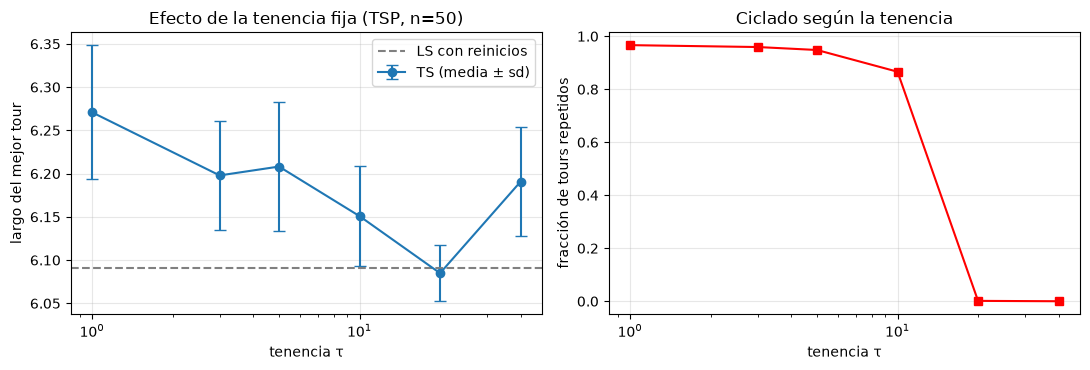

In [5]:
TENENCIAS = [1, 3, 5, 10, 20, 40]
IT = 1500
t0 = time.time()
tab_fija = {}
for tau in TENENCIAS:
    rs = [tabu_tsp(D, IT, np.random.default_rng(s), tenencia=("fija", tau)) for s in SEMILLAS]
    tab_fija[tau] = (np.array([r["mejor"] for r in rs]), np.array([r["rep"] for r in rs]))
print(f"[{time.time()-t0:.1f}s]")
print(f"{'tenencia':>9} | {'mejor (media ± sd)':>20} | {'repetidos (media)':>18}")
for tau in TENENCIAS:
    m, r = tab_fija[tau]
    print(f"{tau:>9} | {resumen(m):>20} | {r.mean():>18.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
mm = [tab_fija[t][0].mean() for t in TENENCIAS]; ss = [tab_fija[t][0].std(ddof=1) for t in TENENCIAS]
ax[0].errorbar(TENENCIAS, mm, yerr=ss, fmt="o-", capsize=4, label="TS (media ± sd)")
ax[0].axhline(np.mean(base_ls), color="gray", ls="--", label="LS con reinicios")
ax[0].set_xscale("log"); ax[0].set_xlabel("tenencia τ"); ax[0].set_ylabel("largo del mejor tour")
ax[0].set_title("Efecto de la tenencia fija (TSP, n=50)"); ax[0].legend()
ax[1].plot(TENENCIAS, [tab_fija[t][1].mean() for t in TENENCIAS], "s-r")
ax[1].set_xscale("log"); ax[1].set_xlabel("tenencia τ"); ax[1].set_ylabel("fracción de tours repetidos")
ax[1].set_title("Ciclado según la tenencia")
plt.tight_layout(); plt.show()

**Lectura.** Con $\tau$ muy pequeño la búsqueda regresa a tours ya vistos (alta fracción de repetidos); al crecer $\tau$ el ciclado
desaparece y la calidad mejora hasta un punto, tras el cual una tenencia excesiva deja pocos movimientos permitidos y la búsqueda
se vuelve más errática. El valor adecuado crece con el tamaño del problema (clásicamente $\tau\sim\sqrt{n}$ a $n$), y por eso
las variantes aleatoria y reactiva buscan robustez frente a esta calibración.

### 7.2 Aspiración, tenencia aleatoria y tenencia reactiva

In [6]:
CONFIGS = {
    "fija 10, sin aspiración":     dict(tenencia=("fija", 10), aspiracion=False),
    "fija 10, con aspiración":     dict(tenencia=("fija", 10), aspiracion=True),
    "aleatoria [5,15]":            dict(tenencia=("aleatoria", (5, 15))),
    "aleatoria [2,30]":            dict(tenencia=("aleatoria", (2, 30))),
    "reactiva (τ0=3)":             dict(tenencia=("reactiva", 3)),
    "fija 3, con aspiración":      dict(tenencia=("fija", 3)),
}
t0 = time.time()
out_cfg = {}
for nombre, kw in CONFIGS.items():
    rs = [tabu_tsp(D, IT, np.random.default_rng(s), **kw) for s in SEMILLAS]
    out_cfg[nombre] = ([r["mejor"] for r in rs], np.mean([r["rep"] for r in rs]), np.mean([r["ten_final"] for r in rs]))
print(f"[{time.time()-t0:.1f}s]")
print(f"{'configuración':<26} | {'mejor (media ± sd)':>20} | {'repetidos':>9} | {'τ final (media)':>15}")
for nombre, (m, rp, tf) in out_cfg.items():
    print(f"{nombre:<26} | {resumen(m):>20} | {rp:>9.3f} | {tf:>15.1f}")
print("LS con reinicios            |", resumen(base_ls))

[6.8s]
configuración              |   mejor (media ± sd) | repetidos | τ final (media)
fija 10, sin aspiración    |      6.1654 ± 0.0592 |     0.857 |            10.0
fija 10, con aspiración    |      6.1508 ± 0.0576 |     0.866 |            10.0
aleatoria [5,15]           |      6.0853 ± 0.0321 |     0.061 |             8.7
aleatoria [2,30]           |      6.0763 ± 0.0247 |     0.000 |            12.4
reactiva (τ0=3)            |      6.0629 ± 0.0098 |     0.023 |            29.5
fija 3, con aspiración     |      6.1979 ± 0.0632 |     0.959 |             3.0
LS con reinicios            | 6.0908 ± 0.0205


La **tenencia reactiva** adapta $\tau$ a la dinámica observada: parte de un valor pequeño y lo aumenta cuando detecta ciclos.
El $\tau$ final promedio de la tabla muestra a qué valor se estabiliza por sí sola. La **aspiración** solo afecta a movimientos
tabú que superan al mejor global; en este tamaño de instancia la diferencia entre "con" y "sin" aspiración es pequeña (compara las
dos primeras filas con sus desviaciones estándar).

Para visualizar la adaptación mostramos la evolución del largo actual en una corrida con tenencia fija pequeña, otra con tenencia
moderada y otra reactiva.

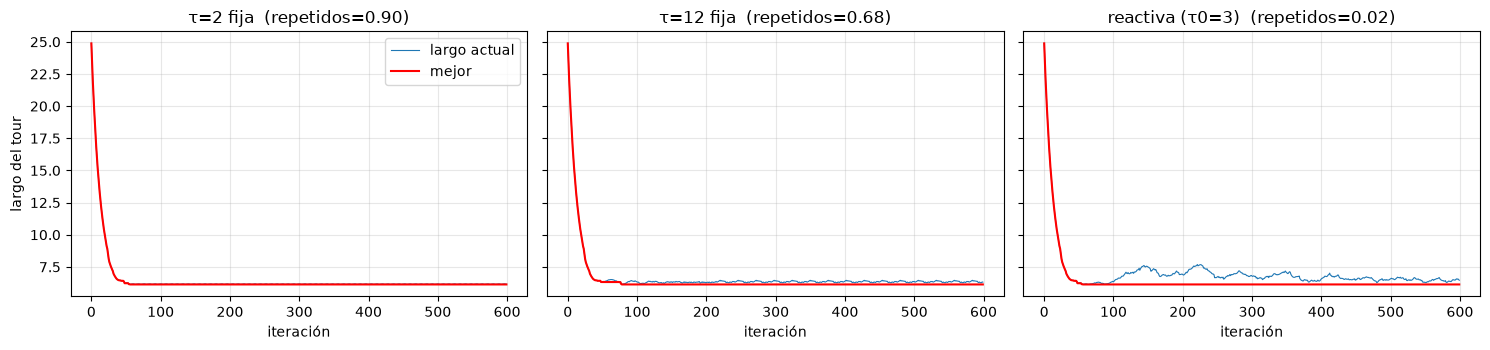

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for a_, (nom, kw) in zip(ax, [("τ=2 fija", dict(tenencia=("fija", 2))),
                              ("τ=12 fija", dict(tenencia=("fija", 12))),
                              ("reactiva (τ0=3)", dict(tenencia=("reactiva", 3)))]):
    r = tabu_tsp(D, 600, np.random.default_rng(3), registrar=True, **kw)
    a_.plot(r["act"], lw=0.8, label="largo actual"); a_.plot(r["mej"], "r", lw=1.5, label="mejor")
    a_.set_title(f"{nom}  (repetidos={r['rep']:.2f})"); a_.set_xlabel("iteración")
ax[0].set_ylabel("largo del tour"); ax[0].legend()
plt.tight_layout(); plt.show()

## 8. Tabú sobre atributos vs. sobre soluciones

Prohibir **soluciones completas** ya visitadas es la forma más exacta de evitar ciclos, pero:
(i) obliga a guardar y consultar todas las soluciones, (ii) solo detecta repeticiones exactas, no regiones casi idénticas, y
(iii) evalúa el hash del tour resultante para cada candidato. Prohibir **atributos** (aristas) es mucho más barato y con una sola
regla bloquea todo un conjunto de soluciones, con el riesgo de prohibir soluciones nunca visitadas (de ahí la aspiración).

In [8]:
t0 = time.time()
comp = {}
for nombre, kw in {"atributos (aristas), τ=10": dict(tipo="atributos", tenencia=("fija", 10)),
                   "soluciones completas":       dict(tipo="soluciones")}.items():
    tt = time.time()
    rs = [tabu_tsp(D, 600, np.random.default_rng(s), **kw) for s in SEMILLAS]
    comp[nombre] = ([r["mejor"] for r in rs], np.mean([r["rep"] for r in rs]), (time.time() - tt) / len(SEMILLAS))
print(f"{'variante':<28} | {'mejor (600 it.)':>20} | {'repetidos':>9} | {'seg/corrida':>11}")
for k, (m, rp, tm) in comp.items():
    print(f"{k:<28} | {resumen(m):>20} | {rp:>9.3f} | {tm:>11.2f}")

variante                     |      mejor (600 it.) | repetidos | seg/corrida
atributos (aristas), τ=10    |      6.1508 ± 0.0576 |     0.680 |        0.04
soluciones completas         |      6.1781 ± 0.0650 |     0.000 |        0.09


**Lectura.** La diferencia entre ambas variantes no supera una desviación estándar de la tabla: con 10 semillas no es
concluyente cuál es mejor en calidad. La diferencia clara es el costo: prohibir soluciones obliga a calcular el hash de los
tours candidatos (segundos/corrida de la tabla), mientras que los atributos se comprueban con una sola indexación matricial.

## 9. Lista de candidatos

Evaluar todo el vecindario cuesta $O(n^2)$ por iteración. Una **lista de candidatos** restringe los movimientos a los que
agregan una arista hacia uno de los $k$ vecinos más cercanos, reduciendo mucho el vecindario sin perder las aristas
prometedoras (en TSP euclídeo las aristas de buenos tours conectan casi siempre vecinos cercanos).
Medimos calidad y fracción del vecindario que queda activo.

In [9]:
Ks = [None, 20, 10, 5, 3]
I50, J50 = pares_2opt(N_TSP)
print(f"{'k_cand':>7} | {'movimientos activos':>20} | {'mejor (media ± sd)':>20} | {'seg/corrida':>11}")
cand_res = {}
for kc in Ks:
    tt = time.time()
    rs = [tabu_tsp(D, IT, np.random.default_rng(s), tenencia=("fija", 10), k_cand=kc) for s in SEMILLAS]
    tm = (time.time() - tt) / len(SEMILLAS)
    if kc:
        nn = mascara_knn(D, kc); t_ = np.random.default_rng(0).permutation(N_TSP)
        act = np.mean([ (nn[t_[I50], t_[J50]] | nn[np.roll(t_, -1)[I50], np.roll(t_, -1)[J50]]).mean()
                        for t_ in [np.random.default_rng(q).permutation(N_TSP) for q in range(20)]])
    else:
        act = 1.0
    cand_res[kc] = [r["mejor"] for r in rs]
    print(f"{str(kc):>7} | {act:>19.1%} | {resumen(cand_res[kc]):>20} | {tm:>11.2f}")

 k_cand |  movimientos activos |   mejor (media ± sd) | seg/corrida


   None |              100.0% |      6.1508 ± 0.0576 |        0.12


     20 |               72.8% |      6.1508 ± 0.0576 |        0.13


     10 |               42.7% |      6.1508 ± 0.0576 |        0.13


      5 |               23.0% |      6.1357 ± 0.0569 |        0.13


      3 |               14.7% |      6.2357 ± 0.1801 |        0.13


*(El porcentaje activo se estima sobre tours aleatorios; en tours buenos los vecinos cercanos aparecen más a menudo como
aristas candidatas, así que la fracción efectiva cambia a lo largo de la búsqueda.)* En esta implementación vectorizada el
costo por iteración está dominado por el overhead de NumPy, por lo que el tiempo casi no cambia; en una implementación con bucles
explícitos (o en C) la reducción del vecindario sí se traduce en tiempo.

## 10. Memoria de mediano y largo plazo

### 10.1 Largo plazo: penalización por frecuencia (diversificación)
Se acumula $F_{uv}$ = número de veces que la arista $(u,v)$ fue **agregada** a la solución actual. Al elegir el movimiento se
suma una penalización a su puntaje (no a la comprobación de aspiración):

$$
\text{puntaje}(m) = \Delta(m) + \lambda\,\bar d\,\frac{F_{u_1v_1}+F_{u_2v_2}}{k}
$$

con $\bar d$ la distancia media (escala) y $k$ la iteración. Con $\lambda>0$ se desincentivan movimientos que repiten aristas
que la búsqueda ya usó muchas veces, empujándola hacia regiones nuevas.

### 10.2 Mediano plazo: intensificación con élites
Se mantiene un pool de las `elite_k` mejores soluciones distintas. Cuando pasan `paciencia` iteraciones sin mejorar el mejor
global, se **reinicia desde una élite elegida al azar** limpiando la lista tabú: se re-explora el entorno de las zonas
prometedoras con una trayectoria nueva.

[6.8s]
variante                       |   mejor (media ± sd) |      mín | reinicios
base (τ=10)                    |      6.1508 ± 0.0576 |   6.0595 |       0.0
+ frecuencia λ=0.5             |      6.1092 ± 0.0588 |   6.0595 |       0.0
+ frecuencia λ=2               |      6.0683 ± 0.0269 |   6.0474 |       0.0
+ élites (paciencia 100)       |      6.1366 ± 0.0529 |   6.0595 |      13.6
+ élites + frecuencia λ=0.5    |      6.1049 ± 0.0488 |   6.0595 |      13.2
aleatoria [5,15] + élites      |      6.0916 ± 0.0430 |   6.0595 |      13.2


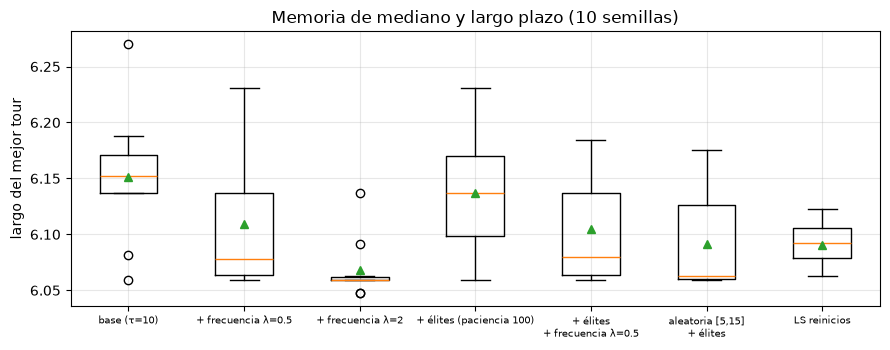

In [10]:
CFG_LP = {
    "base (τ=10)":                    dict(tenencia=("fija", 10)),
    "+ frecuencia λ=0.5":             dict(tenencia=("fija", 10), lam=0.5),
    "+ frecuencia λ=2":               dict(tenencia=("fija", 10), lam=2.0),
    "+ élites (paciencia 100)":       dict(tenencia=("fija", 10), paciencia=100),
    "+ élites + frecuencia λ=0.5":    dict(tenencia=("fija", 10), paciencia=100, lam=0.5),
    "aleatoria [5,15] + élites":      dict(tenencia=("aleatoria", (5, 15)), paciencia=100),
}
t0 = time.time()
res_lp = {}
for nombre, kw in CFG_LP.items():
    rs = [tabu_tsp(D, IT, np.random.default_rng(s), **kw) for s in SEMILLAS]
    res_lp[nombre] = ([r["mejor"] for r in rs], np.mean([r["reinicios"] for r in rs]))
print(f"[{time.time()-t0:.1f}s]")
print(f"{'variante':<30} | {'mejor (media ± sd)':>20} | {'mín':>8} | {'reinicios':>9}")
for k, (m, rr) in res_lp.items():
    print(f"{k:<30} | {resumen(m):>20} | {min(m):>8.4f} | {rr:>9.1f}")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.boxplot([res_lp[k][0] for k in CFG_LP] + [base_ls], tick_labels=[k.replace(" + ", "\n+ ") for k in CFG_LP] + ["LS reinicios"], showmeans=True)
ax.set_ylabel("largo del mejor tour"); ax.set_title("Memoria de mediano y largo plazo (10 semillas)")
plt.xticks(fontsize=7); plt.tight_layout(); plt.show()

La comparación es honesta: si una variante no supera a la base en media (o lo hace por menos que una desviación estándar), no
podemos afirmar mejora con 10 semillas. Los mecanismos de mediano y largo plazo suelen rendir más en corridas largas e
instancias difíciles que en tours de 50 ciudades con pocos miles de iteraciones, donde la memoria de corto plazo ya hace casi
todo el trabajo.

## 11. Trayectoria de la búsqueda

Visualizamos (a) el largo actual y el mejor, (b) la **distancia en aristas** de cada tour visitado al mejor tour final
(cuántas aristas difieren) y (c) el mejor tour encontrado. La distancia en aristas es
$d_E(s,s^*) = n - |E(s)\cap E(s^*)|$.

τ=10 fija: largo inicial 27.495 -> mejor 6.137 (it. 43); tours distintos entre las it. 100 y 800: 22 de 701; distancia media al mejor: 8.7 aristas de 50.


τ aleatoria en [5,15]: largo inicial 27.495 -> mejor 6.137 (it. 43); tours distintos entre las it. 100 y 800: 672 de 701; distancia media al mejor: 10.9 aristas de 50.


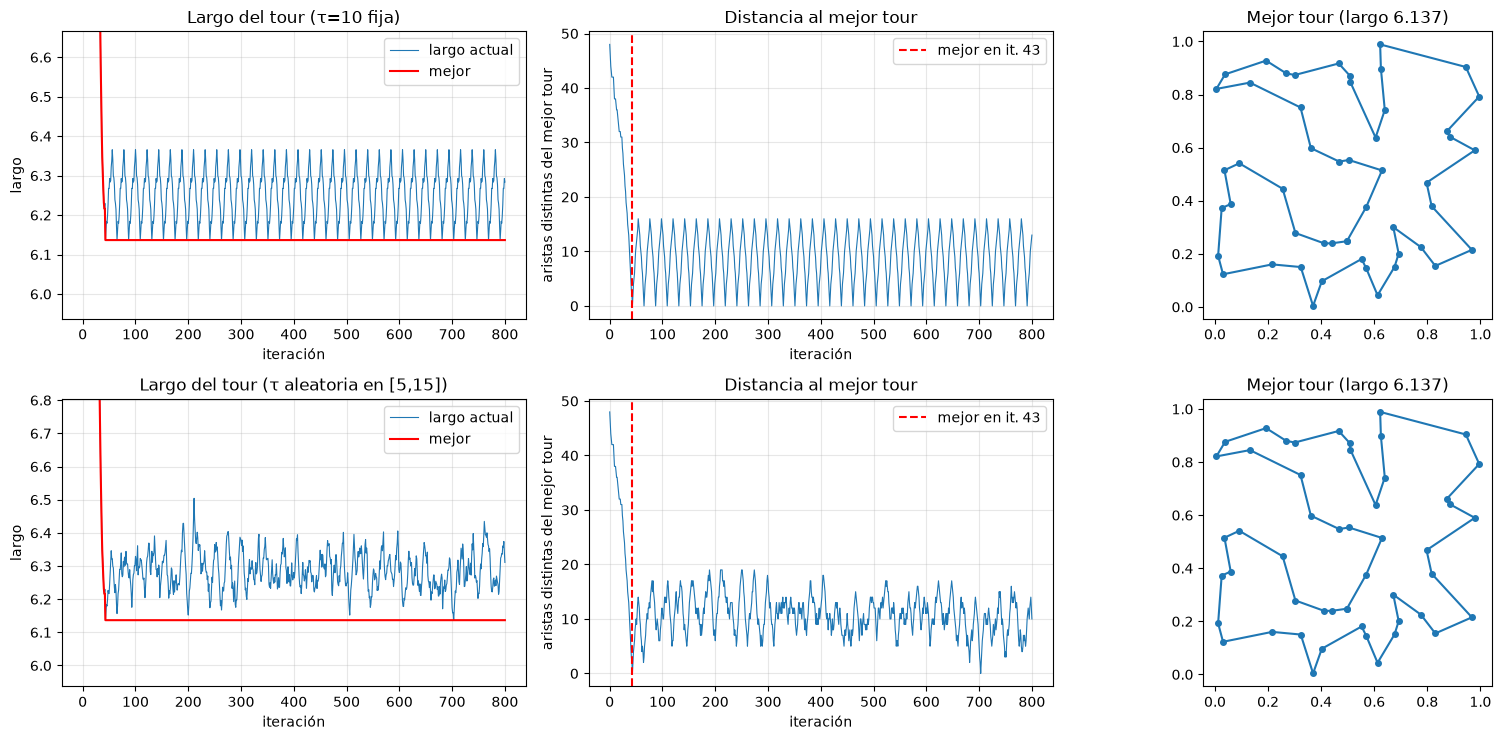

In [11]:
def aristas(t):
    a = t; b = np.roll(t, -1)
    return set(map(frozenset, zip(a.tolist(), b.tolist())))

def dist_aristas(t1, t2):
    return len(t1) - len(aristas(t1) & aristas(t2))

def trayectoria(D, iters, rng, **kw):
    # Misma dinámica que tabu_tsp pero devolviendo los tours visitados (para medir distancias).
    n = len(D); I, J = pares_2opt(n)
    t = rng.permutation(n); L = largo_tour(D, t); E = np.zeros((n, n), dtype=np.int64)
    tau = kw.get("tau", 10); tours = [t.copy()]; Ls = [L]      # tau: entero o (lo, hi) para tenencia aleatoria
    for it in range(1, iters + 1):
        a = t; b = np.roll(t, -1)
        delta = deltas_2opt(D, t, I, J)
        tabu = (E[a[I], a[J]] >= it) | (E[b[I], b[J]] >= it)
        mej = min(Ls)
        ok = ~tabu | (L + delta < mej - 1e-12)
        c = np.where(ok, delta, np.inf); k = int(np.argmin(c))
        i, j = int(I[k]), int(J[k])
        ten = tau if np.isscalar(tau) else int(rng.integers(tau[0], tau[1] + 1))
        for (u, v) in ((a[i], b[i]), (a[j], b[j])):
            E[u, v] = E[v, u] = it + ten
        t = aplicar_2opt(t, i, j); L += delta[k]
        tours.append(t.copy()); Ls.append(L)
    return tours, np.array(Ls)

fig, ax = plt.subplots(2, 3, figsize=(16, 7.5))
for fila, (nom, tau) in enumerate([("τ=10 fija", 10), ("τ aleatoria en [5,15]", (5, 15))]):
    tours, Ls = trayectoria(D, 800, np.random.default_rng(11), tau=tau)
    kbest = int(np.argmin(Ls)); t_star = tours[kbest]
    dist_star = np.array([dist_aristas(t_, t_star) for t_ in tours])
    assert all(es_permutacion(t_, N_TSP) for t_ in tours)
    assert abs(largo_tour(D, tours[-1]) - Ls[-1]) < 1e-8      # el delta acumulado no deriva
    ax[fila, 0].plot(Ls, lw=0.8, label="largo actual"); ax[fila, 0].plot(np.minimum.accumulate(Ls), "r", label="mejor")
    ax[fila, 0].set_ylim(Ls.min() - 0.2, Ls[60:].max() + 0.3)
    ax[fila, 0].set_xlabel("iteración"); ax[fila, 0].set_ylabel("largo"); ax[fila, 0].set_title(f"Largo del tour ({nom})"); ax[fila, 0].legend()
    ax[fila, 1].plot(dist_star, lw=0.8); ax[fila, 1].axvline(kbest, color="r", ls="--", label=f"mejor en it. {kbest}")
    ax[fila, 1].set_xlabel("iteración"); ax[fila, 1].set_ylabel("aristas distintas del mejor tour"); ax[fila, 1].set_title("Distancia al mejor tour"); ax[fila, 1].legend()
    tt = t_star[np.r_[0:N_TSP, 0]]
    ax[fila, 2].plot(P[tt, 0], P[tt, 1], "o-", ms=4)
    ax[fila, 2].set_title(f"Mejor tour (largo {Ls[kbest]:.3f})"); ax[fila, 2].set_aspect("equal"); ax[fila, 2].grid(False)
    distintos = len({clave_tour(t_) for t_ in tours[100:]})
    print(f"{nom}: largo inicial {Ls[0]:.3f} -> mejor {Ls.min():.3f} (it. {kbest}); tours distintos entre las it. 100 y 800: "
          f"{distintos} de 701; distancia media al mejor: {dist_star[100:].mean():.1f} aristas de {N_TSP}.")
plt.tight_layout(); plt.show()

La curva muestra que el largo actual **no es monótono** (TS acepta empeoramientos forzados por la lista tabú) y que, tras el
descenso inicial, la búsqueda **orbita** cerca de los mejores tours. Pero fíjate en la fila de $\tau=10$ fija: la distancia al mejor
tour es **estrictamente periódica**, es decir, la trayectoria cayó en un **ciclo límite** (el "tours distintos" impreso lo confirma:
muy pocos tours únicos en 700 iteraciones). Es exactamente el ciclado que la tenencia aleatoria rompe: con $\tau\in[5,15]$
la trayectoria recorre muchos más tours distintos. Esa es la razón visual de las diferencias de la sección 7.

## 12. *Robust Tabu Search* (Taillard) para el QAP

### 12.1 El problema

Dadas matrices de flujo $F$ y de distancia $B$ ($n\times n$), asignar $n$ unidades a $n$ ubicaciones con permutación $\pi$:

$$
f(\pi)=\sum_{i=1}^n\sum_{j=1}^n F_{ij}\,B_{\pi(i)\pi(j)} .
$$

### 12.2 Delta de un intercambio

Intercambiar las ubicaciones de las unidades $r$ y $s$ (denotamos $\pi'=\pi\circ(r\,s)$) cambia el costo en

$$
\Delta(\pi,r,s)=(F_{rr}-F_{ss})(B_{\pi_s\pi_s}-B_{\pi_r\pi_r})+(F_{rs}-F_{sr})(B_{\pi_s\pi_r}-B_{\pi_r\pi_s})
+\sum_{k\ne r,s}\big[(F_{kr}-F_{ks})(B_{\pi_k\pi_s}-B_{\pi_k\pi_r})+(F_{rk}-F_{sk})(B_{\pi_s\pi_k}-B_{\pi_r\pi_k})\big]
$$

que cuesta $O(n)$ por vecino, es decir $O(n^3)$ por iteración para todo el vecindario.

### 12.3 Actualización $O(1)$ por par

Si ya tenemos la matriz $\Delta$ de la permutación $\pi$ y aplicamos el intercambio $(r,s)$ obteniendo $\pi'$, para cada par
$(i,j)$ **disjunto** de $\{r,s\}$ el nuevo delta es (Taillard, 1991)

$$
\Delta(\pi',i,j)=\Delta(\pi,i,j)+(F_{ri}-F_{rj}+F_{sj}-F_{si})(B_{\pi'_s\pi'_i}-B_{\pi'_s\pi'_j}+B_{\pi'_r\pi'_j}-B_{\pi'_r\pi'_i})
+(F_{ir}-F_{jr}+F_{js}-F_{is})(B_{\pi'_i\pi'_s}-B_{\pi'_j\pi'_s}+B_{\pi'_j\pi'_r}-B_{\pi'_i\pi'_r}).
$$

Solo las filas/columnas $r$ y $s$ requieren recomputo completo ($O(n)$ cada una, $O(n^2)$ en total). Así la iteración completa
baja de $O(n^3)$ a $O(n^2)$. Verificamos ambas fórmulas numéricamente, incluso con matrices **asimétricas**.

In [12]:
def crear_qap(n, rng, simetrica=True):
    # Flujo y distancia enteros aleatorios con diagonal nula.
    Fm = rng.integers(0, 10, (n, n)); Bm = rng.integers(1, 10, (n, n))
    if simetrica:
        Fm = np.triu(Fm, 1); Fm = Fm + Fm.T
        Bm = np.triu(Bm, 1); Bm = Bm + Bm.T
    np.fill_diagonal(Fm, 0); np.fill_diagonal(Bm, 0)
    return Fm, Bm

def costo_qap(Fm, Bm, p):
    return int((Fm * Bm[np.ix_(p, p)]).sum())

def delta_qap(Fm, Bm, p, r, s):
    # Delta general (matrices posiblemente asimétricas) de intercambiar las ubicaciones de r y s. O(n).
    d = (Fm[r, r] - Fm[s, s]) * (Bm[p[s], p[s]] - Bm[p[r], p[r]]) + (Fm[r, s] - Fm[s, r]) * (Bm[p[s], p[r]] - Bm[p[r], p[s]])
    k = np.ones(len(p), bool); k[[r, s]] = False
    pk = p[k]
    d += ((Fm[k, r] - Fm[k, s]) * (Bm[pk, p[s]] - Bm[pk, p[r]])).sum()
    d += ((Fm[r, k] - Fm[s, k]) * (Bm[p[s], pk] - Bm[p[r], pk])).sum()
    return d

def matriz_delta(Fm, Bm, p):
    n = len(p); M = np.zeros((n, n))
    for r in range(n):
        for s in range(r + 1, n):
            M[r, s] = M[s, r] = delta_qap(Fm, Bm, p, r, s)
    return M

def actualizar_delta(Fm, Bm, p_nuevo, M, r, s):
    # Actualiza la matriz de deltas tras intercambiar (r,s); p_nuevo es la permutación YA intercambiada.
    p = p_nuevo
    ar, as_ = Fm[r, :], Fm[s, :]; ac_r, ac_s = Fm[:, r], Fm[:, s]
    br_s, br_r = Bm[p[s], p], Bm[p[r], p]          # b_{π'(s),π'(i)} y b_{π'(r),π'(i)} como vectores en i
    bc_s, bc_r = Bm[p, p[s]], Bm[p, p[r]]          # b_{π'(i),π'(s)} y b_{π'(i),π'(r)}
    t1 = (ar[:, None] - ar[None, :] + as_[None, :] - as_[:, None])
    t2 = (br_s[:, None] - br_s[None, :] + br_r[None, :] - br_r[:, None])
    u1 = (ac_r[:, None] - ac_r[None, :] + ac_s[None, :] - ac_s[:, None])
    u2 = (bc_s[:, None] - bc_s[None, :] + bc_r[None, :] - bc_r[:, None])
    N = M + t1 * t2 + u1 * u2
    n = len(p)
    for x in (r, s):                               # filas/columnas r y s: recomputo completo
        for k in range(n):
            if k != x:
                N[x, k] = N[k, x] = delta_qap(Fm, Bm, p, x, k)
    np.fill_diagonal(N, 0)
    return N

# Verificación 1: delta O(n) vs recomputación del costo, matrices asimétricas.
rng = np.random.default_rng(5)
for sim in (True, False):
    Fq, Bq = crear_qap(15, rng, simetrica=sim)
    p = rng.permutation(15)
    e1 = 0
    for r in range(15):
        for s in range(r + 1, 15):
            q = p.copy(); q[[r, s]] = q[[s, r]]
            e1 = max(e1, abs((costo_qap(Fq, Bq, q) - costo_qap(Fq, Bq, p)) - delta_qap(Fq, Bq, p, r, s)))
    # Verificación 2: actualización O(1) vs matriz recomputada, tras 200 intercambios aleatorios.
    M = matriz_delta(Fq, Bq, p); e2 = 0
    for _ in range(200):
        r, s = rng.choice(15, 2, replace=False)
        p[[r, s]] = p[[s, r]]
        M = actualizar_delta(Fq, Bq, p, M, r, s)
        e2 = max(e2, np.abs(M - matriz_delta(Fq, Bq, p)).max())
    print(f"simétrica={sim!s:5}: error delta O(n) = {e1:.0f}, error máx de la matriz actualizada tras 200 swaps = {e2:.0f}")

simétrica=True : error delta O(n) = 0, error máx de la matriz actualizada tras 200 swaps = 0


simétrica=False: error delta O(n) = 0, error máx de la matriz actualizada tras 200 swaps = 0


### 12.4 La búsqueda: *Robust Tabu Search*

Reglas de Taillard (1991):

- **Atributo tabú:** el par (unidad $i$, ubicación $\ell$). Tras intercambiar $r$ y $s$ se prohíbe que $r$ vuelva a su antigua
  ubicación y que $s$ vuelva a la suya durante $\tau$ iteraciones.
- **Movimiento tabú:** un intercambio es tabú si **ambas** unidades pasarían a ubicaciones que ocupaban recientemente.
- **Tenencia aleatoria:** $\tau$ se sortea uniformemente en $[0.9n,\,1.1n]$ en cada iteración (de ahí "robusta": poco sensible a
  la calibración).
- **Aspiración:** (a) por objetivo (mejora el mejor global), y (b) por *antigüedad* (diversificación forzada): si existen intercambios
  cuyas **dos** asignaciones no se han visto hace más de $A$ iteraciones, se elige el mejor de ellos aunque otro movimiento
  tenga menor delta. Así ningún movimiento queda ignorado indefinidamente.
- **Sin criterio de parada local:** siempre se ejecuta el movimiento permitido de menor delta (empates al azar).

In [13]:
def rots_qap(Fm, Bm, iters, rng, tenencia=(0.9, 1.1), aspiracion_edad=None, p0=None, registrar=False, usar_update=True):
    # Robust Tabu Search para el QAP. tenencia=(a,b): τ ~ U{a·n, ..., b·n}.
    n = len(Fm)
    p = rng.permutation(n) if p0 is None else p0.copy()
    c = costo_qap(Fm, Bm, p); mejor, p_mejor = c, p.copy()
    M = matriz_delta(Fm, Bm, p)
    tabu = np.zeros((n, n), dtype=np.int64)            # tabu[i,l]: hasta cuándo no puede i volver a l
    ultima = np.zeros((n, n), dtype=np.int64)   # ultima[i,l]: última iteración en que i dejó l
    R, S = np.triu_indices(n, 1)
    lo, hi = max(1, int(round(tenencia[0] * n))), max(1, int(round(tenencia[1] * n)))
    h_act, h_mej = [], []; forzados = 0
    for it in range(1, iters + 1):
        d = M[R, S]
        es_tabu = (tabu[R, p[S]] >= it) & (tabu[S, p[R]] >= it)
        ok = ~es_tabu | (c + d < mejor)                  # aspiración por objetivo
        if aspiracion_edad is not None:                  # aspiración por antigüedad: diversificación forzada
            viejo = (ultima[R, p[S]] < it - aspiracion_edad) & (ultima[S, p[R]] < it - aspiracion_edad)
            if viejo.any():
                ok = viejo; forzados += 1
        cand = np.where(ok, d, np.inf)
        mn = cand.min()
        if not np.isfinite(mn):
            k = int(rng.integers(len(R)))
        else:
            k = int(rng.choice(np.flatnonzero(cand == mn)))
        r, s = int(R[k]), int(S[k])
        pr, ps = p[r], p[s]
        # actualizar tabú antes de mover: r no vuelve a pr, s no vuelve a ps
        tabu[r, pr] = it + int(rng.integers(lo, hi + 1)); tabu[s, ps] = it + int(rng.integers(lo, hi + 1))
        ultima[r, pr] = it; ultima[s, ps] = it
        c += int(d[k])
        p[r], p[s] = ps, pr
        M = actualizar_delta(Fm, Bm, p, M, r, s) if usar_update else matriz_delta(Fm, Bm, p)
        if c < mejor:
            mejor, p_mejor = c, p.copy()
        if registrar:
            h_act.append(c); h_mej.append(mejor)
    assert es_permutacion(p_mejor, n) and costo_qap(Fm, Bm, p_mejor) == mejor
    return dict(mejor=mejor, perm=p_mejor, act=np.array(h_act), mej=np.array(h_mej), forzados=forzados)

N_Q = 20
Fq, Bq = crear_qap(N_Q, np.random.default_rng(21))

# Comparación de tiempos: actualización O(1) por par vs recomputo completo de la matriz de deltas
t0 = time.time(); r1 = rots_qap(Fq, Bq, 300, np.random.default_rng(0), usar_update=True); t_up = time.time() - t0
t0 = time.time(); r2 = rots_qap(Fq, Bq, 300, np.random.default_rng(0), usar_update=False); t_full = time.time() - t0
print(f"300 iteraciones: con actualización {t_up:.2f}s | recomputando toda la matriz {t_full:.2f}s | "
      f"misma trayectoria: {r1['mejor'] == r2['mejor'] and np.array_equal(r1['perm'], r2['perm'])}")

300 iteraciones: con actualización 0.16s | recomputando toda la matriz 0.72s | misma trayectoria: True


Ambas versiones producen **exactamente la misma trayectoria** (mismo mejor costo y permutación; las semillas coinciden), pero
la actualización incremental es varias veces más rápida: la ventaja crece con $n$.

### 12.5 Efecto de la tenencia y comparación con búsqueda local con reinicios

Referencia: búsqueda local de *mejor mejora* con intercambios y reinicios aleatorios con el mismo número de vecindarios evaluados.

[54.2s]
  τ ~ U[0.9fn, 1.1fn], f |     costo (media ± sd) |    mín
                     0.1 |       7014.2 ±   85.3 |   6924
                    0.25 |       6850.2 ±   20.6 |   6824
                     0.5 |       6842.8 ±   20.4 |   6824
                     1.0 |       6836.2 ±    8.6 |   6824
                     2.0 |       6864.0 ±   26.4 |   6824
                     4.0 |       6876.5 ±   48.3 |   6824
        LS con reinicios |       6920.8 ±   29.0 |   6874


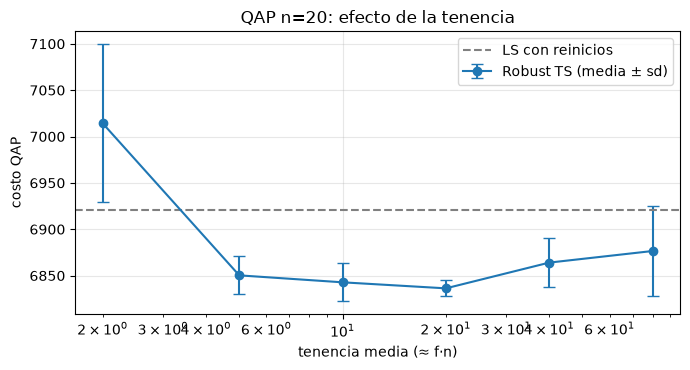

In [14]:
def ls_qap(Fm, Bm, p, rng):
    # Búsqueda local mejor-mejora con intercambios; usa la actualización de deltas. Devuelve (perm, costo, pasos).
    n = len(p); p = p.copy(); c = costo_qap(Fm, Bm, p)
    M = matriz_delta(Fm, Bm, p); R, S = np.triu_indices(n, 1); pasos = 0
    while True:
        d = M[R, S]; k = int(np.argmin(d))
        if d[k] >= 0:
            return p, c, pasos
        r, s = int(R[k]), int(S[k]); c += int(d[k]); p[r], p[s] = p[s], p[r]
        M = actualizar_delta(Fm, Bm, p, M, r, s); pasos += 1

def ls_reinicios_qap(Fm, Bm, presupuesto, rng):
    n = len(Fm); gastado = 0; mejor = np.inf
    while gastado < presupuesto:
        _, c, pasos = ls_qap(Fm, Bm, rng.permutation(n), rng)
        gastado += pasos + 1; mejor = min(mejor, c)
    return mejor

IT_Q = 1500; SEM_Q = list(range(8))
factores = [0.1, 0.25, 0.5, 1.0, 2.0, 4.0]
t0 = time.time()
q_res = {}
for f in factores:
    rs = [rots_qap(Fq, Bq, IT_Q, np.random.default_rng(s), tenencia=(0.9 * f, 1.1 * f))["mejor"] for s in SEM_Q]
    q_res[f] = np.array(rs)
ls_q = np.array([ls_reinicios_qap(Fq, Bq, IT_Q, np.random.default_rng(s)) for s in SEM_Q])
print(f"[{time.time()-t0:.1f}s]")
print(f"{'τ ~ U[0.9fn, 1.1fn], f':>24} | {'costo (media ± sd)':>22} | {'mín':>6}")
for f in factores:
    print(f"{f:>24} | {q_res[f].mean():>12.1f} ± {q_res[f].std(ddof=1):>6.1f} | {q_res[f].min():>6}")
print(f"{'LS con reinicios':>24} | {ls_q.mean():>12.1f} ± {ls_q.std(ddof=1):>6.1f} | {ls_q.min():>6}")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.errorbar([f * N_Q for f in factores], [q_res[f].mean() for f in factores], yerr=[q_res[f].std(ddof=1) for f in factores],
            fmt="o-", capsize=4, label="Robust TS (media ± sd)")
ax.axhline(ls_q.mean(), color="gray", ls="--", label="LS con reinicios")
ax.set_xscale("log"); ax.set_xlabel("tenencia media (≈ f·n)"); ax.set_ylabel("costo QAP"); ax.legend()
ax.set_title(f"QAP n={N_Q}: efecto de la tenencia"); plt.tight_layout(); plt.show()

Observa que, a diferencia del TSP, en el QAP la tenencia **debe ser del orden de $n$**: con tenencias pequeñas el espacio de
$\binom{n}{2}$ intercambios se revisita en ciclos cortos.

### 12.6 Trayectoria en QAP y aspiración por antigüedad

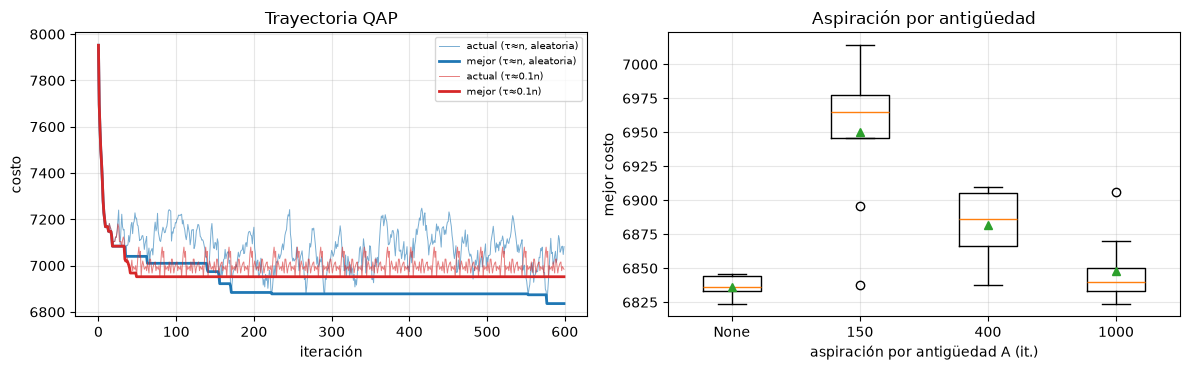

A= None: 6836.2 ± 8.6   (iteraciones con selección forzada: 0)


A=  150: 6950.2 ± 56.3   (iteraciones con selección forzada: 1343)


A=  400: 6881.5 ± 28.4   (iteraciones con selección forzada: 217)


A= 1000: 6848.0 ± 27.6   (iteraciones con selección forzada: 13)


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for nom, kw, col in [("τ≈n, aleatoria", dict(), "C0"), ("τ≈0.1n", dict(tenencia=(0.09, 0.11)), "C3")]:
    r = rots_qap(Fq, Bq, 600, np.random.default_rng(2), registrar=True, **kw)
    ax[0].plot(r["act"], lw=0.7, color=col, alpha=0.6, label=f"actual ({nom})")
    ax[0].plot(r["mej"], lw=2, color=col, label=f"mejor ({nom})")
ax[0].set_xlabel("iteración"); ax[0].set_ylabel("costo"); ax[0].set_title("Trayectoria QAP"); ax[0].legend(fontsize=7)

asp_vals = [None, 150, 400, 1000]
res_a = {a: np.array([rots_qap(Fq, Bq, IT_Q, np.random.default_rng(s), aspiracion_edad=a)["mejor"] for s in SEM_Q]) for a in asp_vals}
ax[1].boxplot([res_a[a] for a in asp_vals], tick_labels=[str(a) for a in asp_vals], showmeans=True)
ax[1].set_xlabel("aspiración por antigüedad A (it.)"); ax[1].set_ylabel("mejor costo"); ax[1].set_title("Aspiración por antigüedad")
plt.tight_layout(); plt.show()
for a in asp_vals:
    fz = np.mean([rots_qap(Fq, Bq, IT_Q, np.random.default_rng(s), aspiracion_edad=a)["forzados"] for s in SEM_Q[:3]])
    print(f"A={str(a):>5}: {res_a[a].mean():.1f} ± {res_a[a].std(ddof=1):.1f}   (iteraciones con selección forzada: {fz:.0f})")

**Lectura.** La selección forzada por antigüedad es una herramienta de diversificación con un costo: con $A$ pequeño (muchas
iteraciones forzadas, ver la última columna) desvía la búsqueda de los mejores movimientos y empeora el resultado; con $A$ grande
casi no se activa y se acerca a la versión sin ella. En esta instancia y presupuesto no aporta mejora; Taillard la reserva para
corridas largas, con $A\sim n^2$ o más.

## 13. Ventajas y limitaciones

| Aspecto | Ventajas | Limitaciones |
|---|---|---|
| Exploración | determinista y dirigida por memoria; atraviesa óptimos locales sin aleatoriedad pura | requiere evaluar (casi) todo el vecindario por iteración |
| Parámetros | pocos y interpretables ($\tau$, aspiración); variantes aleatoria/reactiva reducen la calibración | $\tau$ depende del tamaño y del problema; atributos mal elegidos prohíben demasiado o muy poco |
| Cálculo incremental | deltas $O(1)$ / $O(n)$ y matriz de deltas en QAP hacen cada iteración barata | el esquema $O(1)$ es específico del problema; hay que derivarlo y verificarlo |
| Diversificación | memoria de largo plazo y reinicios desde élites controlan intensificación/diversificación | agregan hiperparámetros ($\lambda$, paciencia, tamaño de élite) cuyo beneficio depende de la instancia |
| Garantías | en la práctica, excelente con vecindarios bien diseñados | sin garantía de optimalidad; puede ciclar con ciclos largos no detectados |

## Resumen
- La búsqueda tabú = **mejor vecino permitido** + **memoria** que prohíbe deshacer movimientos recientes + **aspiración**.
- La **tenencia** controla el equilibrio ciclado vs. estrangulamiento; la aleatoria y la reactiva la hacen más robusta.
- Prohibir **atributos** es barato y cubre muchas soluciones; prohibir **soluciones** es exacto pero costoso y menos general.
- Las **listas de candidatos** reducen el vecindario; la **frecuencia** y las **élites** añaden diversificación e intensificación.
- En QAP, la actualización $O(1)$ de la matriz de deltas (verificada) permite iteraciones $O(n^2)$ y es la base de *Robust Tabu Search*.
- Toda comparación debe incluir una línea base (búsqueda local con reinicios) y varias semillas con media $\pm$ desviación.

## Ejercicios propuestos
1. Implementa la tenencia reactiva completa de Battiti-Tecchiolli (con escape por ciclos caóticos) y compárala con la versión simplificada de este notebook.
2. En el TSP, cambia el atributo tabú: prohíbe **quitar** aristas recién agregadas (en lugar de reagregar las eliminadas). ¿Cambia el ciclado?
3. Usa un vecindario *Or-opt* o 3-opt acotado con lista de candidatos y estudia el compromiso calidad/tiempo.
4. Añade memoria de largo plazo al QAP: penaliza (unidad, ubicación) frecuentes y mide el efecto sobre la media en 20 semillas.
5. Mide cómo escala la tenencia óptima del TSP con $n\in\{30,50,80\}$; ajusta una ley de potencias.
6. Reemplaza el reinicio desde élite por *path relinking* entre élites ([notebook 07](07-grasp-path-relinking.ipynb)).
7. Compara TS con recocido simulado ([notebook 05](../01-metodos-de-trayectoria/05-aleatorizados-recocido-simulado.ipynb)) con presupuestos de evaluación iguales.

## Referencias
- Glover, F. (1986). *Future paths for integer programming and links to artificial intelligence*. Computers & Operations Research, 13(5).
- Glover, F. (1989, 1990). *Tabu Search – Part I* y *Part II*. ORSA Journal on Computing, 1(3) y 2(1).
- Glover, F. & Laguna, M. (1997). *Tabu Search*. Kluwer Academic Publishers.
- Taillard, É. (1991). *Robust taboo search for the quadratic assignment problem*. Parallel Computing, 17.
- Battiti, R. & Tecchiolli, G. (1994). *The reactive tabu search*. ORSA Journal on Computing, 6(2).
- Gendreau, M. & Potvin, J.-Y. (eds.) (2010). *Handbook of Metaheuristics* (2.ª ed.), capítulo sobre Tabu Search. Springer.